# 06 · Simulación de producción

**Pregunta:** ¿cómo se armó la producción simulada y qué respondió la API en cada lote?

- Patrón **batch semanal**: cada lote de simulación es una semana de cocción (sección 5 del PSet 4).
- Lotes 1 a 9: los 45 lotes reales del conjunto de prueba del PSet 3 (17/08 al 12/10/2026), posteriores a la fecha de corte del entrenamiento.
- Lote 10: **deriva inducida** (`src/preparar_simulacion.py`): 6 lotes reales con `carga_planta_14d` + 12 y `generacion_levadura` 4 o 5. La merma real no se tocó.
- Las predicciones las hizo la API desde el flujo `kestra/produccion_lotes.yml` y quedaron en `PRODUCCION.PREDICCIONES` (exportada a `docs/predicciones.csv` con `src/exportar_evidencia.py`).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SIM = RAIZ / "data" / "simulacion"
DOCS = RAIZ / "docs"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Los lotes de la simulación

In [2]:
sim = pd.read_csv(SIM / "lotes_simulacion.csv", dtype={"numero_documento": str})
resumen = (sim.groupby("lote_simulacion")
              .agg(semana=("semana", "first"), deriva=("deriva", "max"),
                   lotes_cerveza=("numero_documento", "size"), merma_alta=("merma_alta", "sum")))
resumen["pct_merma_alta"] = (resumen["merma_alta"] / resumen["lotes_cerveza"]).round(2)
resumen

,semana,deriva,lotes_cerveza,merma_alta,pct_merma_alta
lote_simulacion,,,,,
1,2026-08-17,0,6,5,0.83
2,2026-08-24,0,6,6,1.00
3,2026-08-31,0,6,5,0.83
4,2026-09-07,0,6,5,0.83
5,2026-09-14,0,5,3,0.60
6,2026-09-21,0,3,3,1.00
7,2026-09-28,0,5,4,0.80
8,2026-10-05,0,6,4,0.67
9,2026-10-12,0,2,1,0.50


Las semanas tienen entre 2 y 6 lotes de cerveza (limitación: las métricas por semana son inestables). El 80 % de los lotes de la simulación tuvo merma alta, frente al 64 % del entrenamiento.

## 2. Qué cambió en el lote con deriva

In [3]:
variables = ["carga_planta_14d", "generacion_levadura", "levadura_nueva", "sin_generacion"]
comparacion = sim.groupby("deriva")[variables].mean().round(2)
comparacion.index = ["lotes normales (1-9)", "lote con deriva (10)"]
comparacion

,carga_planta_14d,generacion_levadura,levadura_nueva,sin_generacion
lotes normales (1-9),10.76,1.02,0.3,0.11
lote con deriva (10),22.33,4.50,0.0,0.00


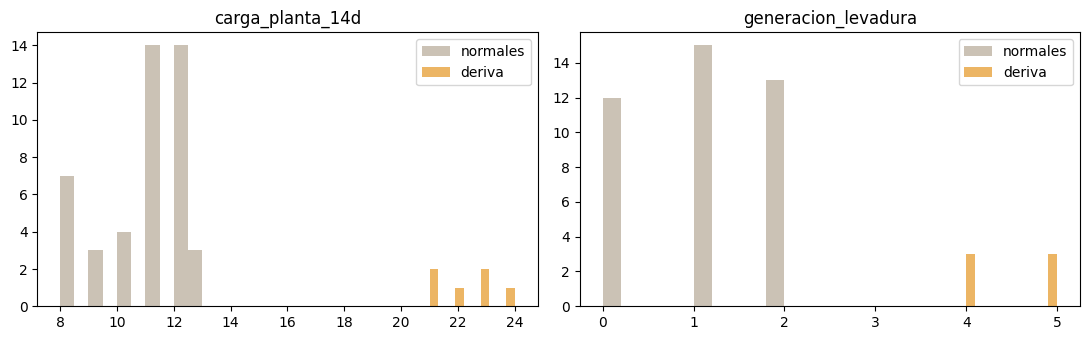

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
for eje, v in zip(ejes, ["carga_planta_14d", "generacion_levadura"]):
    for d, color, nombre in [(0, "#BFB3A3", "normales"), (1, "#E8A33D", "deriva")]:
        eje.hist(sim.loc[sim["deriva"] == d, v].dropna(), bins=10, alpha=0.8, color=color, label=nombre)
    eje.set_title(v)
    eje.legend()
plt.tight_layout()
plt.show()

## 3. Lo que respondió la API

In [5]:
pred = pd.read_csv(DOCS / "predicciones.csv", dtype={"numero_documento": str})
pred = pred[pred["lote_simulacion"].notna()]
# Última predicción de cada lote de cerveza (un lote reenviado deja dos filas)
pred = (pred.sort_values("timestamp_prediccion")
            .drop_duplicates(["lote_simulacion", "numero_documento"], keep="last"))
por_lote = (pred.groupby("lote_simulacion")
                .agg(predicciones=("numero_documento", "size"),
                     con_clarificante=("decision", lambda d: (d == "aplicar_clarificante").sum()),
                     probabilidad_media=("probabilidad", "mean"),
                     version_modelo=("version_modelo", "first"),
                     respaldo=("respaldo", "sum"),
                     latencia_p95_ms=("latencia_ms", lambda x: x.quantile(0.95))))
por_lote.round(3)

,predicciones,con_clarificante,probabilidad_media,version_modelo,respaldo,latencia_p95_ms
lote_simulacion,,,,,,
1.0,6,2,0.628,1,0,1464.662
2.0,6,5,0.648,1,0,88.055
3.0,6,5,0.618,1,0,48.072
4.0,6,1,0.601,1,0,53.005
5.0,5,3,0.625,1,0,35.810
6.0,3,3,0.622,1,0,52.921
7.0,5,4,0.633,1,0,57.664
8.0,6,2,0.600,1,0,41.580
9.0,2,2,0.637,1,0,1080.016


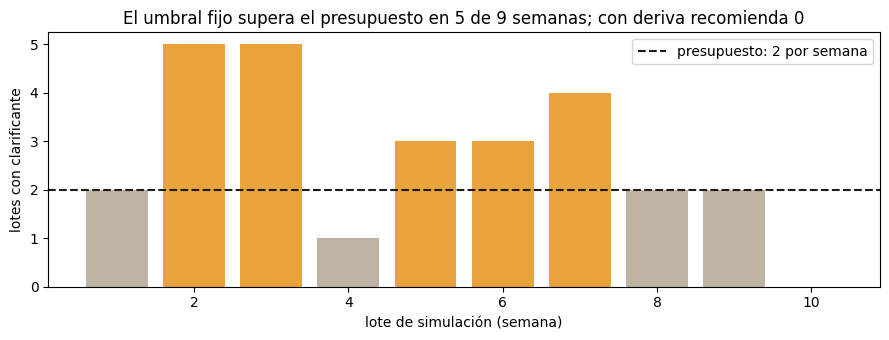

In [6]:
fig, eje = plt.subplots(figsize=(9, 3.5))
colores = ["#E8A33D" if c > 2 else "#BFB3A3" for c in por_lote["con_clarificante"]]
eje.bar(por_lote.index, por_lote["con_clarificante"], color=colores)
eje.axhline(2, color="#1E1A16", linestyle="--", label="presupuesto: 2 por semana")
eje.set_xlabel("lote de simulación (semana)")
eje.set_ylabel("lotes con clarificante")
eje.set_title("El umbral fijo supera el presupuesto en 5 de 9 semanas; con deriva recomienda 0")
eje.legend()
plt.tight_layout()
plt.show()

## 4. Valor de negocio de cada política (sección 9)

In [7]:
valor = pd.read_csv(SIM / "valor_negocio.csv")
valor

,periodo,politica,costo_total_usd,costo_por_lote_usd,clarificantes_usados,semanas_sobre_presupuesto,merma_alta_detectada,clarificante_innecesario,ahorro_vs_hoy_usd
0,"semanas normales (1-9), 45 lotes",sin acción (hoy),4272.00,94.93,0,0,0 de 36,0,0.00
1,"semanas normales (1-9), 45 lotes",regla por estilo (PSet 1),3035.77,67.46,6,0,6 de 36,0,1236.23
2,"semanas normales (1-9), 45 lotes","modelo, umbral fijo",1607.13,35.71,27,5,22 de 36,5,2664.87
3,"semanas normales (1-9), 45 lotes","modelo, top-2 por semana",2705.71,60.13,18,0,14 de 36,4,1566.29
4,"semana con deriva (10), 6 lotes",sin acción (hoy),452.83,75.47,0,0,0 de 5,0,0.00
5,"semana con deriva (10), 6 lotes",regla por estilo (PSet 1),452.83,75.47,0,0,0 de 5,0,0.00
6,"semana con deriva (10), 6 lotes","modelo, umbral fijo",452.83,75.47,0,0,0 de 5,0,0.00
7,"semana con deriva (10), 6 lotes","modelo, top-2 por semana",173.79,28.96,2,0,2 de 5,0,279.04
8,"todas (1-10), 51 lotes",sin acción (hoy),4724.84,92.64,0,0,0 de 41,0,0.00
9,"todas (1-10), 51 lotes",regla por estilo (PSet 1),3488.60,68.40,6,0,6 de 41,0,1236.24


**Lectura:** en las semanas normales, el modelo con umbral fijo baja el costo de los errores de 4.272 a 1.607 USD, pero excede el presupuesto; con el tope de 2 por semana ahorra 1.566 USD, 330 más que la regla por estilo. En la semana con deriva, solo el top-2 ahorra algo (279 USD).